<a href="https://colab.research.google.com/github/m1Febriansyah/244107020199-ML-12/blob/main/JS11Praktikum1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

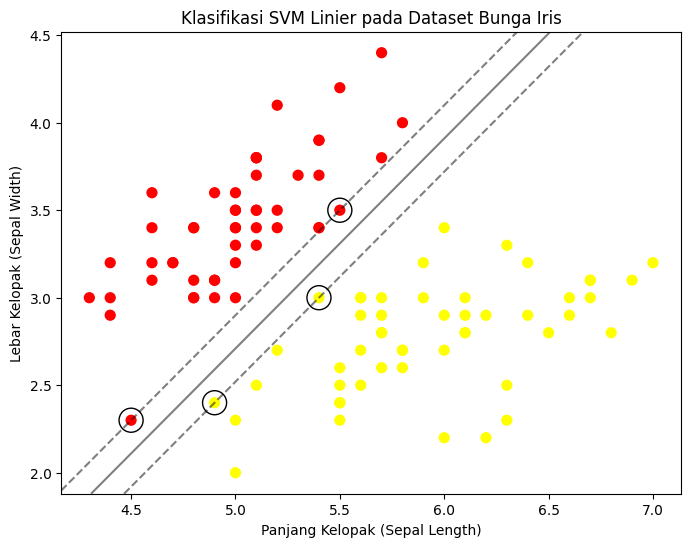

Titik koordinat yang menjadi Support Vector:
[[5.5 3.5]
 [4.5 2.3]
 [4.9 2.4]
 [5.4 3. ]]


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.svm import SVC

# ==========================================
# 1. MENGGUNAKAN DATA NYATA (DATASET IRIS)
# ==========================================
# Load dataset Iris
iris = datasets.load_iris()

# Kita hanya mengambil 100 data pertama (2 kelas bunga: Setosa & Versicolor)
# dan 2 fitur pertama (Panjang & Lebar Kelopak) agar bisa dibuat grafik 2 Dimensi.
X = iris.data[:100, :2]
y = iris.target[:100]

# ==========================================
# 2. MELATIH MODEL SVM (FITTING MODEL)
# ==========================================
# Menggunakan kernel linier sesuai instruksi modul
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

# ==========================================
# 3. FUNGSI VISUALISASI DARI DOSEN
# ==========================================
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x_grid = np.linspace(xlim[0], xlim[1], 30)
    y_grid = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y_grid, x_grid)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    # plot batas dan margin
    ax.contour(X_grid, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors (lingkaran besar)
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='k')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

# ==========================================
# 4. MENAMPILKAN HASIL AKHIR
# ==========================================
plt.figure(figsize=(8, 6))
# Menampilkan titik data bunga Iris
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Memanggil fungsi untuk menggambar garis batas SVM
plot_svc_decision_function(model)

plt.title("Klasifikasi SVM Linier pada Dataset Bunga Iris")
plt.xlabel("Panjang Kelopak (Sepal Length)")
plt.ylabel("Lebar Kelopak (Sepal Width)")
plt.show()

# Menampilkan titik mana saja yang menjadi Support Vector
print("Titik koordinat yang menjadi Support Vector:")
print(model.support_vectors_)